In [25]:
import numpy as np
from collections import defaultdict
from SVM_oracles import *


# Generate SVM classification problem

In [26]:
from sklearn.calibration import LinearSVC
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

"""
Support vector classification problem of Section 7.3.

Given vectors {x_1,...,x_l} ⊂ R^n each of which is classifed
by y_i = 1 or -1, the goal is to find w ∈ R^n and b > 0 such that
the hyperplane w' * x + b splits the data into its two respective
communities. We model this by minimising

    0.5*∥w∥^2 + C ∑_{i=1}^l max(0, 1-y(w' * x_i))^2.
"""
class SupportVectorClassification(OptimizationMethods):
    def __init__(self, x, y, C):
        self.x = x  # matrix with rows corresponding to [x_i; 1]
        self.y = y
        self.C = C

    def func(self, z):
        # z = [w;b]
        w = z[:-1]
        J = 0.5 * np.dot(w, w)
        J += self.C * np.sum(np.maximum(1 - self.y * (self.x @ z), 0) ** 2)
        return J

    def grad(self, z):
        # z = [w;b]
        x, y, C = self.x, self.y, self.C
        a = 1 - y * (x @ z)
        active = a > 0

        gradf = np.zeros_like(z)
        gradf[:-1] = z[:-1]
        gradf += -2 * C * (x[active].T @ (y[active] * a[active]))
        return gradf

    def grad_i(self, z, i):
        x_i = self.x[i]
        y_i = self.y[i]
        n = self.x.shape[0]

        g = np.zeros_like(z)
        g[:-1] = z[:-1]   # not / n

        a = 1.0 - y_i * (x_i @ z)
        if a > 0:
            g += -2.0 * self.C * n * y_i * a * x_i

        return g
    def hess(self, z):
        # z = [w;b]
        x, y, C = self.x, self.y, self.C
        a = 1 - y * (x @ z)
        active = a > 0
        x_active = x[active]
        n = z.shape[0] - 1

        H = np.eye(z.shape[0])
        H[-1, -1] = 0.0
        H += 2 * C * (x_active.T @ x_active)
        return H

    def solve_with_leapssn(self):
        w_0 = 0.5 * np.ones(x.shape[1])
        w_k, status, history = self.leapssn(
            w_0,
            n_iters=150,
            adaptive_search=True,
            # Lambda_0=3 * np.linalg.norm(self.x) * self.C,
            alpha=1e-1,
            beta=1e-1,
            trace=True,
            grad_tol=1e-8,
            adaptive_search_max_iter=100,
        )
        return w_k, history["matrix_inverses"][-1], history

    def solve_with_gradient_method(self):
        w_0 = 0.5 * np.ones(x.shape[1])
        w_k, status, history = self.gradient_method(w_0, max_iter=400)
        return w_k, history
    
    def solve_with_svrg_bb(self, no_epochs=1000):
        w_0 = 0.5 * np.zeros(x.shape[1])
        w_k, status, history = self.svrg_bb(w_0, n_epochs=no_epochs, eta_0=1e-12)
        return w_k, history
        
    def solve_with_cubic_newton(self):
        w_0 = 0.5 * np.ones(x.shape[1])
        w_k, status, history = self.cubic_newton(w_0, n_iters=120)
        return w_k, history
 

    def solve_with_gladssn(self, lazy_Hessians=False, update_freq=1):
        w_0 = 0.5 * np.ones(x.shape[1])
        w_k, status, history = self.gladssn(
            w_0,
            n_iters=100,
            adaptive_search=True,
            # Lambda_0=3 * np.linalg.norm(self.x) * self.C,
            alpha=1e-1,
            beta=1e-1,
            trace=True,
            grad_tol=1e-5,
            adaptive_search_max_iter=100,
            lazy_Hessians=lazy_Hessians,
            update_freq=update_freq,
        )
        return w_k, history["matrix_inverses"][-1], history


# Generate data and run solvers

In [27]:
# Generate a classification set with vectors of size n
def generate_data(n):
    if n == 2:
        X, y = make_classification(
            n_samples=10_000,
            n_features=2,
            n_informative=2,
            n_redundant=0,
            n_clusters_per_class=1,
            flip_y=0.2,
            class_sep=1.5,
            random_state=43,
        )
    else:
        X, y = make_classification(
            n_samples=10_000,
            n_features=n,
            n_clusters_per_class=1,
            flip_y=0.2,
            class_sep=1.5,
            random_state=43,
        )
    y[y == 0] = -1  # make_classification gives y in {0,1} rather than {-1,1}
    x = np.hstack((X.copy(), np.ones((X.shape[0], 1))))
    return x, y



# Generation
x, y = generate_data(1000)
svc = SupportVectorClassification(x, y, 1e4)

# Test that grad_i does the right thing
# z = np.random.randn(svc.x.shape[1])
# g_full = svc.grad(z)
# g_avg = sum(svc.grad_i(z, i) for i in range(svc.x.shape[0])) / svc.x.shape[0]
# print("||g_full - g_avg|| =", np.linalg.norm(g_full - g_avg))
# print("||g_full|| =", np.linalg.norm(g_full))
# print("||g_avg|| =", np.linalg.norm(g_avg))


# Reset NumPy's random stream so solver sampling repeats on each run.
np.random.seed(0)

# GM
print("Running Gradient Method")
xk, history_gradient_method = svc.solve_with_gradient_method()


#SVRG-BB
print("Running SVRG-BB")
xk, history_svrg_bb = svc.solve_with_svrg_bb(no_epochs=500)


# Cubic
print("Running Cubic Method")
_, history_cubic_newton = svc.solve_with_cubic_newton()


# LeapSSN
print("Running LeAPSSN")
x_k, _, history_leapssn = svc.solve_with_leapssn()

# GLaDSSN
print("Running GLAdSSN")
x_k, _, history_gladssn = svc.solve_with_gladssn()
# print("GLAdSSN:", svc.func(x_k))

# Lazy
list_of_lazy_frequencies = ["2", "4", "5", "10"]
histories_gladssn_lazy = {j: defaultdict(list) for j in list_of_lazy_frequencies}
for lazy_freq in list_of_lazy_frequencies:
    print("Running GLAdSSN with lazy frequency", lazy_freq)
    _, _, histories_gladssn_lazy[lazy_freq] = svc.solve_with_gladssn(
        lazy_Hessians=True, update_freq=int(lazy_freq)
    )


Running Gradient Method
Running SVRG-BB
W: svrg_bb diverged at epoch 51
Running Cubic Method
Running LeAPSSN
No of backtracks:  122
Running GLAdSSN
No of backtracks:  13
Running GLAdSSN with lazy frequency 2
No of backtracks:  14
Running GLAdSSN with lazy frequency 4
No of backtracks:  20
Running GLAdSSN with lazy frequency 5
No of backtracks:  17
Running GLAdSSN with lazy frequency 10
No of backtracks:  23


# Define objects needed for plotting

In [28]:
all_histories = {}
all_histories["gradient_method"] = history_gradient_method
all_histories["svrg_bb"] = history_svrg_bb
all_histories["cubic_newton"] = history_cubic_newton
all_histories["leapssn"] = history_leapssn
all_histories["gladssn"] = history_gladssn
all_histories.update(histories_gladssn_lazy)

 


labels = list(all_histories.keys())
labels[labels.index("leapssn")] = "LeAP-SSN"
labels[labels.index("gladssn")] = "GLAd-SSN"
labels[labels.index("gradient_method")] = "Gradient Method"
labels[labels.index("cubic_newton")] = "Cubic Newton"
labels[labels.index("svrg_bb")] = "SVRG-BB"

labels = [f"GLAd-SSN m={x}" if x.isdigit() else x for x in labels]


list_of_mins = [np.min(history["func"]) for history in all_histories.values()]
mn_func = min(list_of_mins)

gradient_method_color = "#E8601C"
svrg_bb_color = "pink"
cubic_newton_color = "gold"  
leapssn_color = "black"
gladssn_color = "#9B8AC4"
gladssn_lazy_1_color = "#88A5DD"
gladssn_lazy_2_color = "#8DCBE4"
gladssn_lazy_3_color = "#C2E3D2"
gladssn_lazy_4_color = "#DDECBF"

colors = [gradient_method_color, svrg_bb_color, cubic_newton_color, leapssn_color, gladssn_color, gladssn_lazy_1_color, gladssn_lazy_2_color, gladssn_lazy_3_color, gladssn_lazy_4_color]

line_widths = [2.0] * len(list(all_histories.keys())) 
line_styles = ["-"] * len(list(all_histories.keys())) 





In [29]:
# Save only the series needed for plotting, so figures can be reformatted later.
import pickle

plot_keys = (
    "time",
    "func",
    "func_at_lssolve",
    "grad_norm",
    "grad_norm_at_lssolve",
)
plot_histories = {
    label: {key: np.asarray(history[key]) for key in plot_keys if key in history}
    for label, history in all_histories.items()
}

with open("svm_results_full.pkl", "wb") as result_file:
    pickle.dump({"histories": plot_histories, "labels": labels}, result_file)

print("Saved plotting data to svm_results_full.pkl")

Saved plotting data to svm_results_full.pkl


# Plots

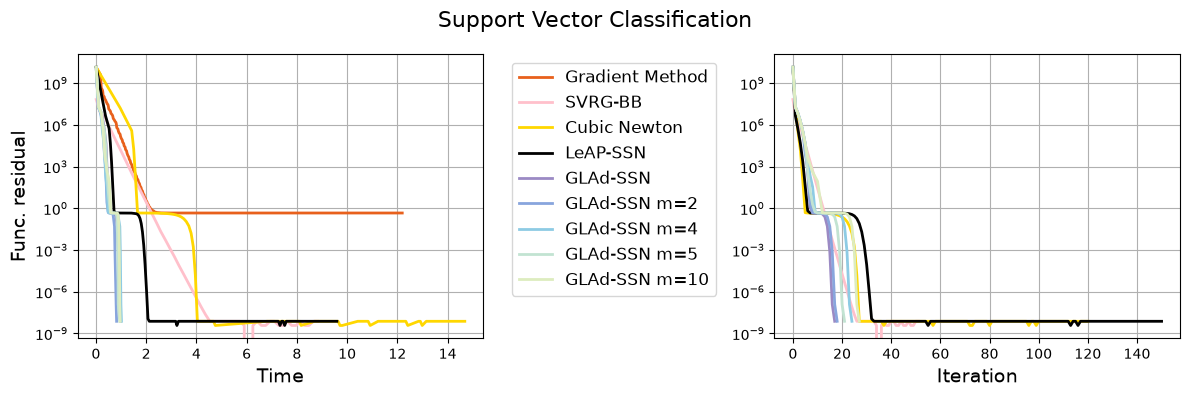

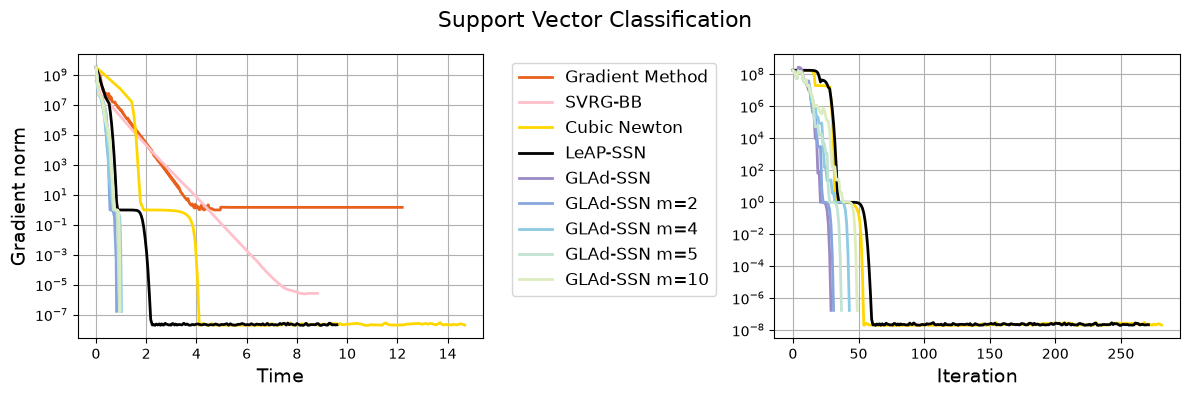

In [30]:

from SVM_utils import *
plot_figures(
    list(all_histories.values()),
    labels,
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Support Vector Classification"),
    which_measure_2="func",
    max_iter=1000,
)

plot_figures(
    list(all_histories.values()),
    labels,
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=0,
    threshold=1e-10,
    suptitle=("Support Vector Classification"),
    max_iter=1000,
    which_measure_1="grad_norm",
    which_measure_2="grad_norm_at_lssolve",
    ylabel="Gradient norm",
)



# Plots for the paper

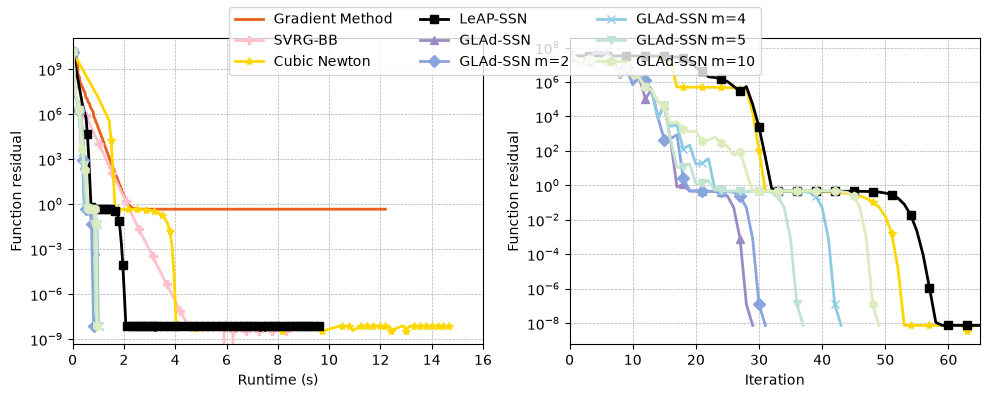

In [31]:
m_cycle = [
"None",   # None Gradient Method
"P",   # plus-filled SVRG-BB
"*",   # star Cubic Newton
"s",   # square LeapSSN
"^",   # triangle up GladSSN
"D",   # diamond GladSSN second
"x",   # x GladSSN third
"v",   # triangle down GladSSN fourth
"h",   # hexagon GladSSN fifth
]
markevery_numbers = [3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

from SVM_utils import plot_for_paper_2

# plot_for_paper(
#     list(all_histories.values()),
#     labels,
#     colors=colors,
#     linewidths=line_widths,
#     linestyles=line_styles,
#     n=100,
#     m=None,
#     mu_str=("0.5"),
#     f_star=mn_func,
#     threshold=1e-10,
#     suptitle=("Support Vector Classification"),
#     max_iter=1000,
#     clip_time=2
# )

plot_for_paper_2(
    list(all_histories.values()),
    labels,
    colors=colors,
    linewidths=line_widths,
    linestyles=line_styles,
    n=100,
    m=None,
    mu_str=("0.5"),
    f_star=mn_func,
    threshold=1e-10,
    suptitle=("Support Vector Classification"),
    max_iter=65,
    clip_time=16,
    m_cycle=m_cycle,
    markevery_numbers=markevery_numbers

)

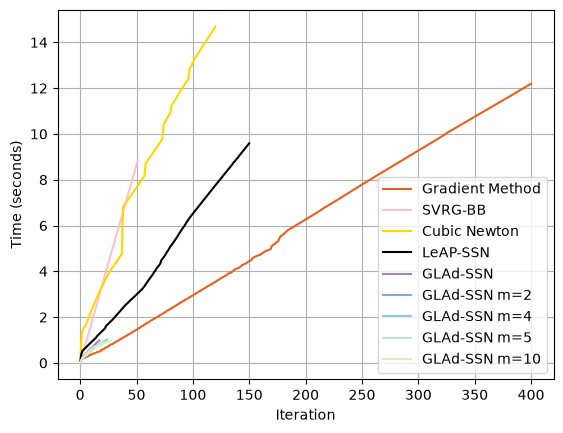

In [32]:
for label, (key, history), color in zip(labels, all_histories.items(), colors):
    times = history["time"]
    iters = range(len(times))
    plt.plot(iters, times, label=label, color=color)

plt.xlabel("Iteration")
plt.ylabel("Time (seconds)")
plt.legend()
plt.grid(True)
plt.show()